In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [29]:
from google.colab import files

uploaded = files.upload()

Saving StudentsPerformance.csv to StudentsPerformance (1).csv


In [30]:
df = pd.read_csv("StudentsPerformance.csv")

print("Dataset loaded successfully!")
df.head()

Dataset loaded successfully!


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


## 1. Dataset Introduction

Dataset Title: Students Performance in Exams

Source: Kaggle

Dataset Link:
https://www.kaggle.com/datasets/spscientist/students-performance-in-exams

This dataset contains information about students' backgrounds,
test preparation, and examination marks.

The main objective is to explore how student characteristics
and preparation relate to academic scores.

Target Variable: math score

In [31]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
df.describe(include="all").T

Dataset shape: (1000, 8)

Column names:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,1000,2,female,518,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race/ethnicity,1000,5,group C,319,NaN,NaN,NaN,NaN,NaN,NaN,NaN
parental level of education,1000,6,some college,226,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lunch,1000,2,standard,645,NaN,NaN,NaN,NaN,NaN,NaN,NaN
test preparation course,1000,2,none,642,NaN,NaN,NaN,NaN,NaN,NaN,NaN
math score,1000.0,NaN,NaN,NaN,66.089,15.16308,0.0,57.0,66.0,77.0,100.0
reading score,1000.0,NaN,NaN,NaN,69.169,14.600192,17.0,59.0,70.0,79.0,100.0
writing score,1000.0,NaN,NaN,NaN,68.054,15.195657,10.0,57.75,69.0,79.0,100.0


In [32]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Missing values:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

Duplicate rows:
0

Data types:
gender                         object
race/ethnicity                 object
parental level of education    object
lunch                          object
test preparation course        object
math score                      int64
reading score                   int64
writing score                   int64
dtype: object


Markdown interpretation

The initial inspection checks whether the dataset contains missing values, duplicate records, or unexpected data types. These checks help determine whether the dataset is suitable for exploratory analysis.

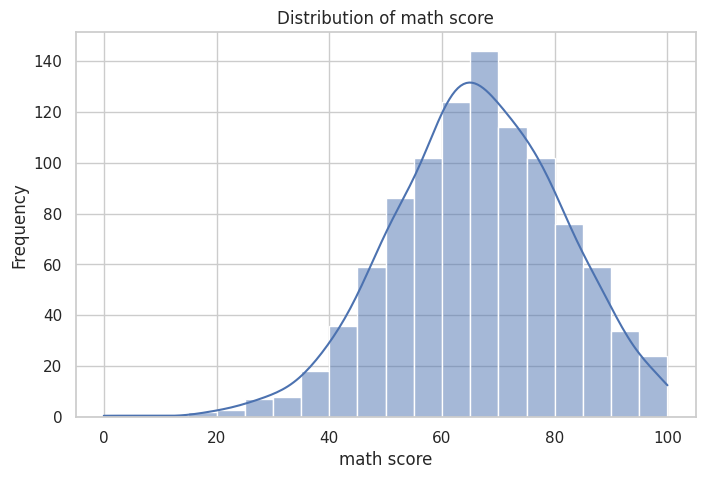

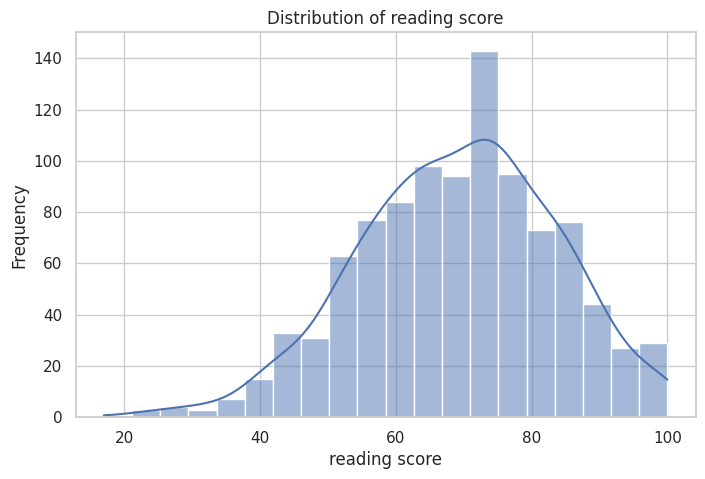

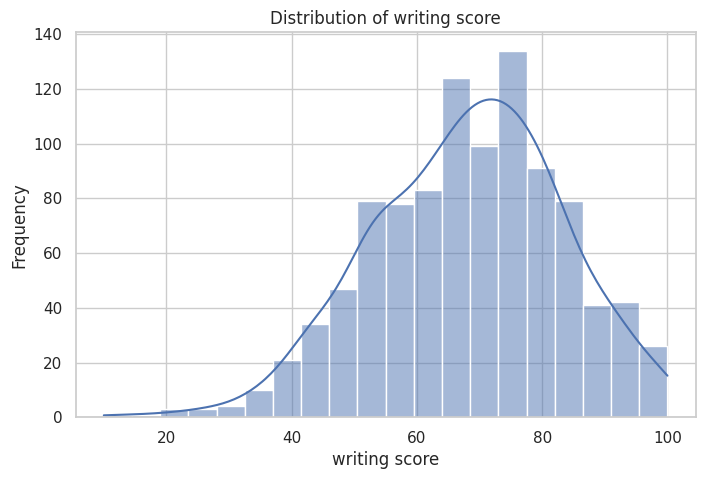

In [33]:
numerical_cols = [
    "math score",
    "reading score",
    "writing score"
]

for col in numerical_cols:

    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=df,
        x=col,
        bins=20,
        kde=True
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.show()

Markdown interpretation

The histograms show how examination scores are distributed. They help identify the most common score ranges, the spread of marks, and whether the distributions are approximately symmetric or skewed.

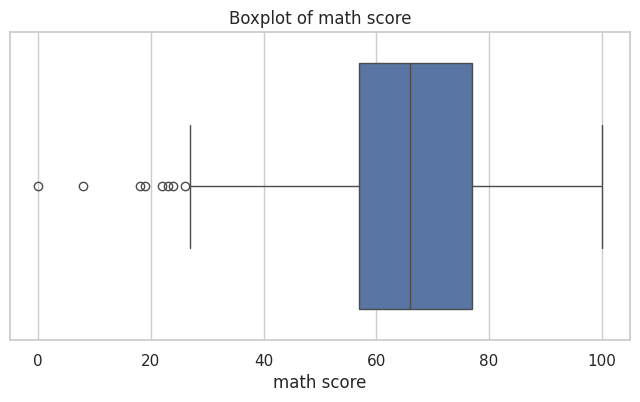

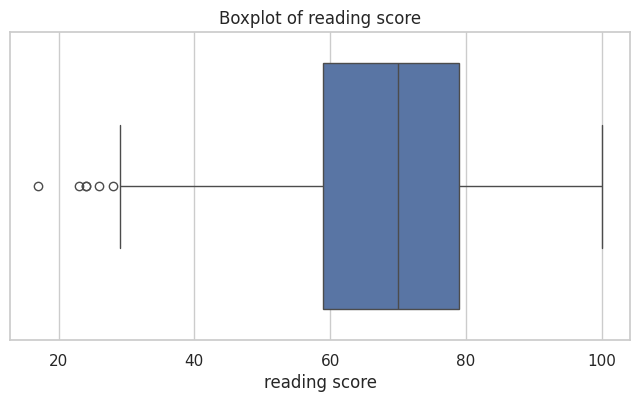

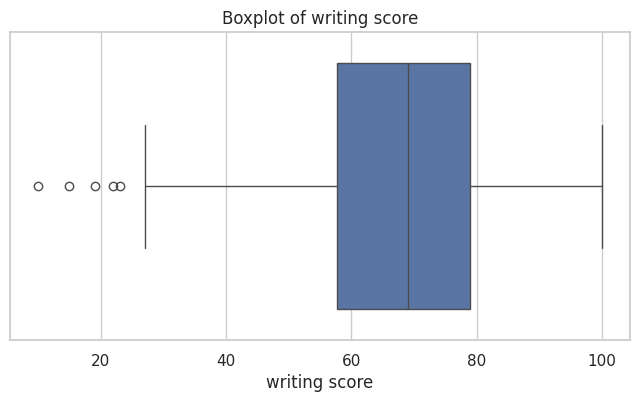

In [34]:
for col in numerical_cols:

    plt.figure(figsize=(8, 4))

    sns.boxplot(data=df, x=col)

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)

    plt.show()

Markdown interpretation

Boxplots display the median, quartiles, and spread of examination scores. Points outside the whiskers represent potential unusual observations that may require further investigation.

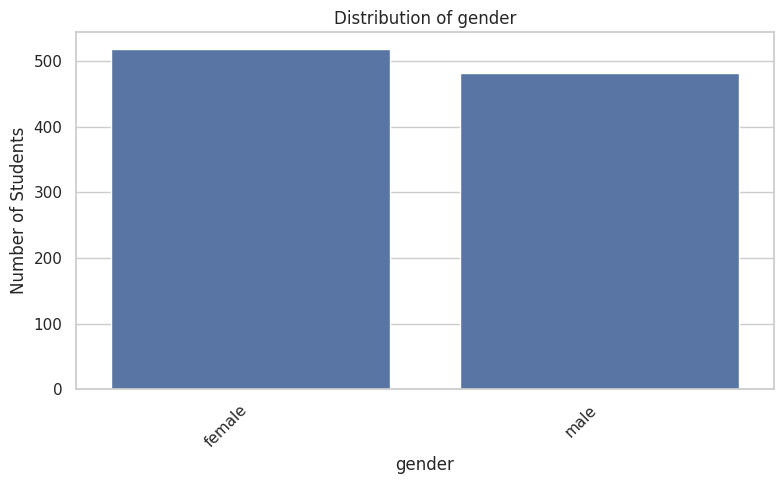

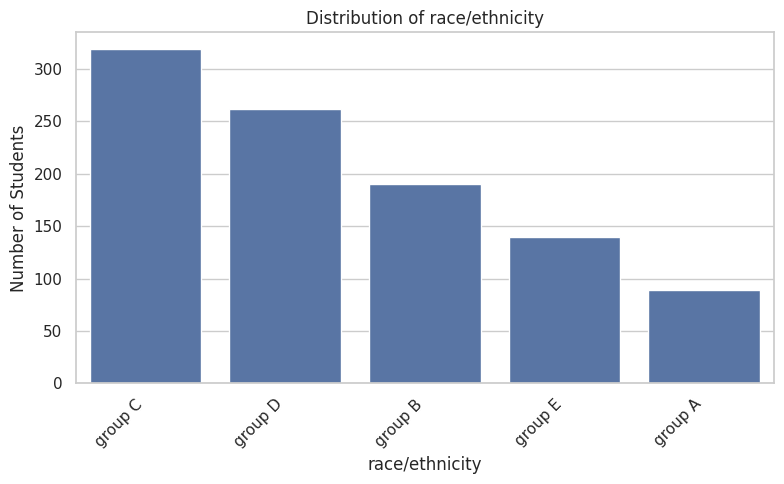

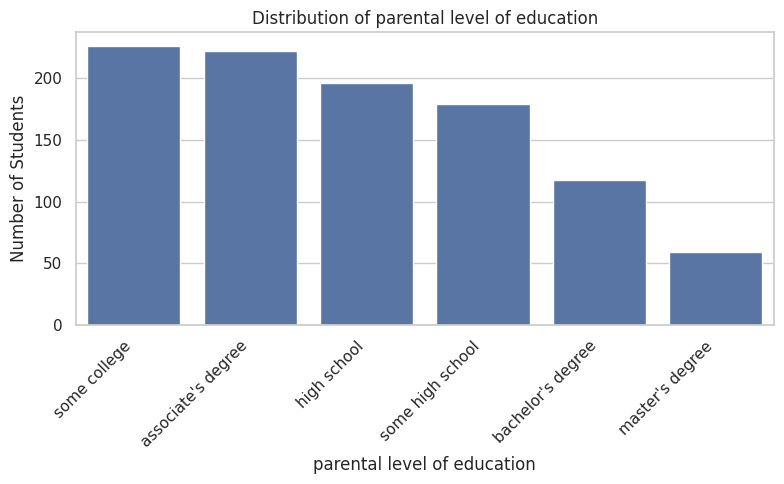

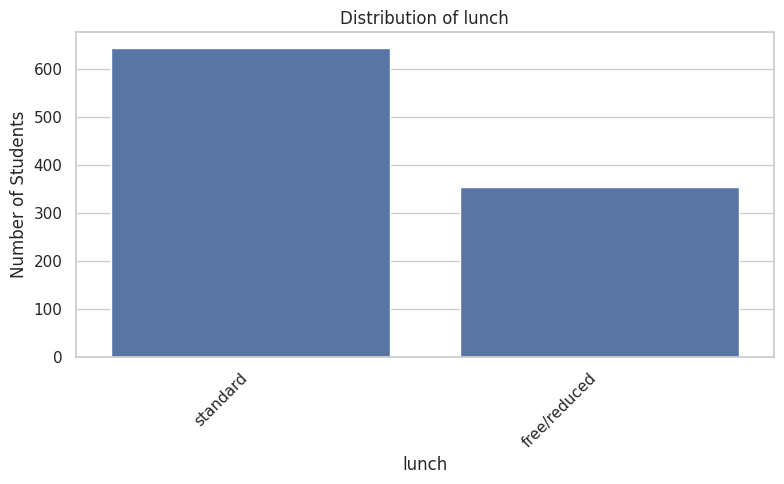

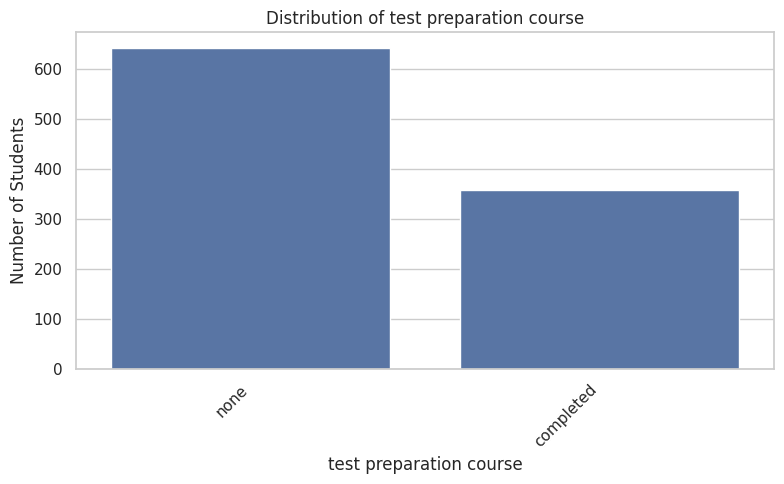

In [35]:
categorical_cols = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course"
]

for col in categorical_cols:

    plt.figure(figsize=(8, 5))

    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        x=col,
        order=order
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Students")

    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    plt.show()

Markdown interpretation

The bar charts show the number of students in each category. They help identify the most common gender, parental education level, lunch type, and test preparation status.

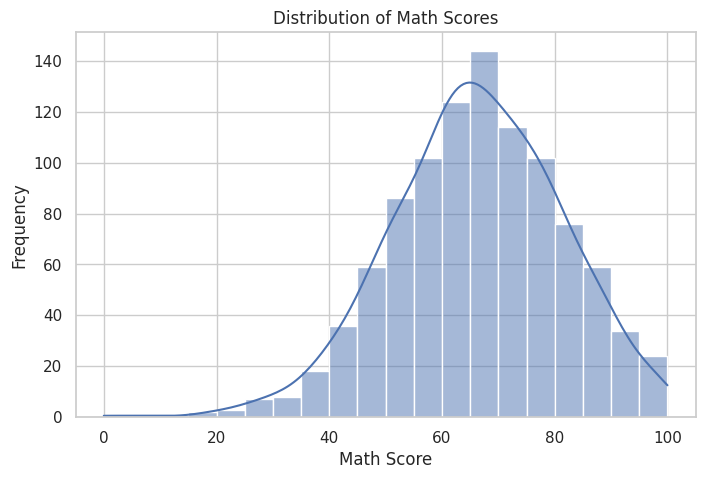

In [36]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="math score",
    bins=20,
    kde=True
)

plt.title("Distribution of Math Scores")
plt.xlabel("Math Score")
plt.ylabel("Frequency")

plt.show()

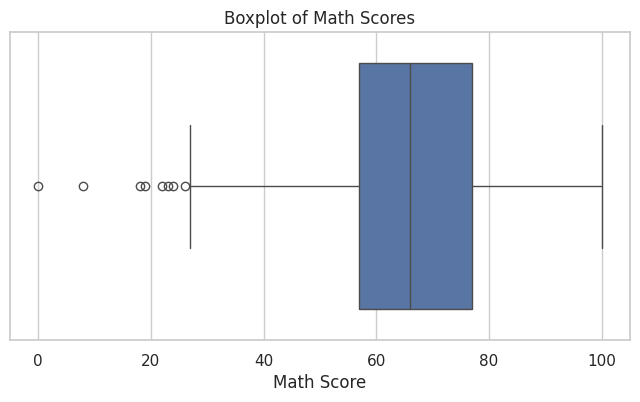

In [37]:
plt.figure(figsize=(8, 4))

sns.boxplot(data=df, x="math score")

plt.title("Boxplot of Math Scores")
plt.xlabel("Math Score")

plt.show()

In [38]:
print("Math Score Statistics")
print(df["math score"].describe())

Math Score Statistics
count    1000.00000
mean       66.08900
std        15.16308
min         0.00000
25%        57.00000
50%        66.00000
75%        77.00000
max       100.00000
Name: math score, dtype: float64


Markdown interpretation

Math score is a numerical target variable. Its histogram and boxplot help identify the typical score range, variation, and possible unusual observations.

Because math score is numerical rather than categorical, it is not appropriate to describe it as balanced or imbalanced in the usual classification sense.

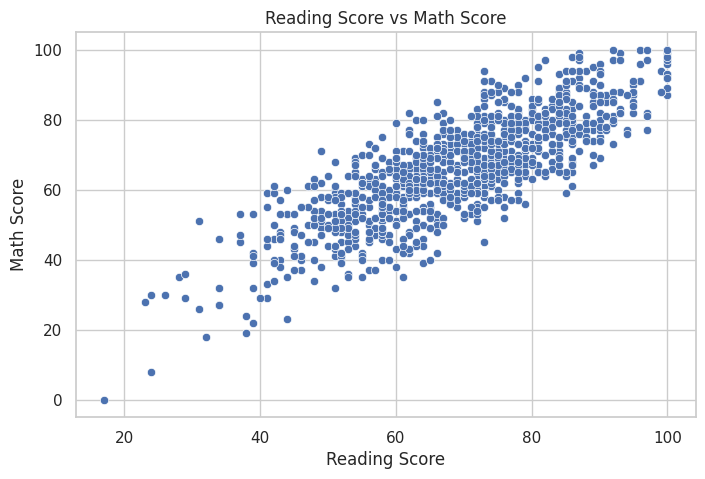

In [39]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="reading score",
    y="math score"
)

plt.title("Reading Score vs Math Score")
plt.xlabel("Reading Score")
plt.ylabel("Math Score")

plt.show()

Interpretation: The scatter plot helps determine whether students with higher reading scores also tend to have higher math scores.

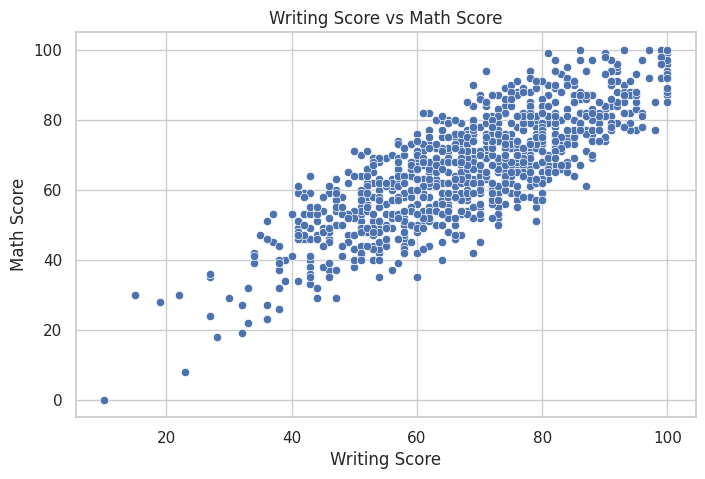

In [40]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="writing score",
    y="math score"
)

plt.title("Writing Score vs Math Score")
plt.xlabel("Writing Score")
plt.ylabel("Math Score")

plt.show()

Interpretation: This graph shows whether writing scores have a visible association with math scores. An upward pattern would indicate a positive relationship.

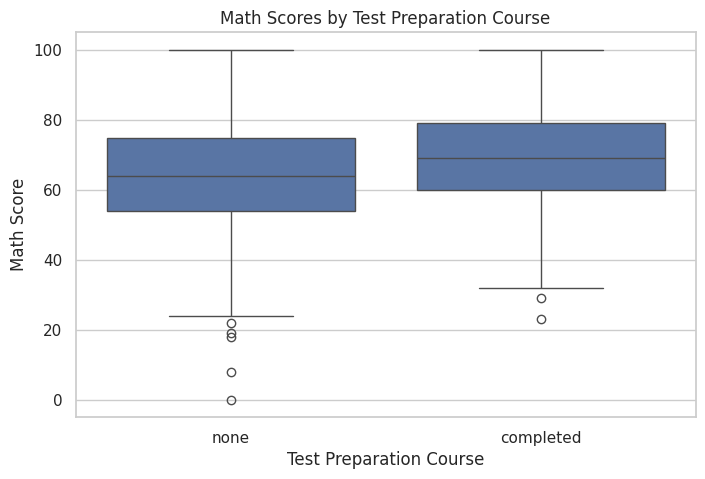

In [41]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="test preparation course",
    y="math score"
)

plt.title("Math Scores by Test Preparation Course")
plt.xlabel("Test Preparation Course")
plt.ylabel("Math Score")

plt.show()

Interpretation: This graph compares the distribution of math scores for students who completed a test preparation course and students who did not. It helps examine whether the groups have different score distributions.

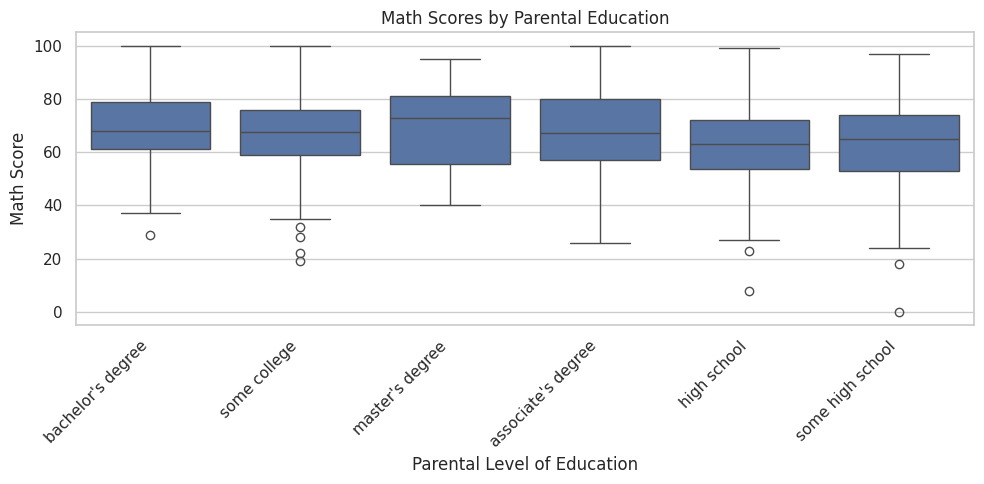

In [42]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="parental level of education",
    y="math score"
)

plt.title("Math Scores by Parental Education")
plt.xlabel("Parental Level of Education")
plt.ylabel("Math Score")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

Interpretation: The boxplots compare math score distributions across parental education categories. Differences between groups may suggest an association between parental education and student performance.

In [43]:
correlation_matrix = df[numerical_cols].corr()

print(correlation_matrix)

               math score  reading score  writing score
math score       1.000000       0.817580       0.802642
reading score    0.817580       1.000000       0.954598
writing score    0.802642       0.954598       1.000000


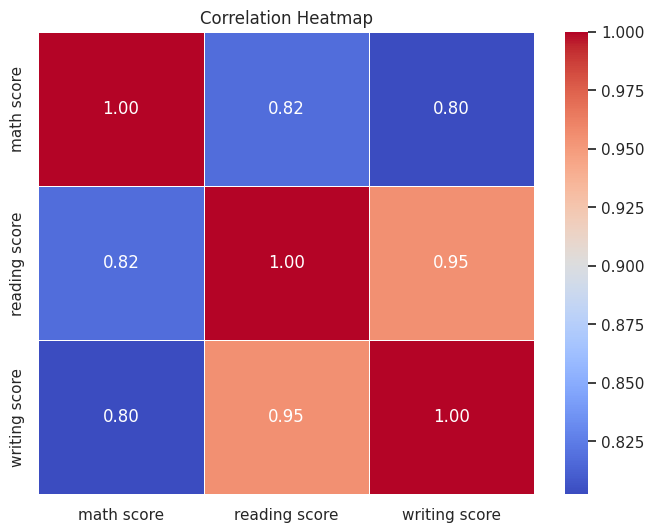

In [44]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")

plt.show()

Interpretation

Correlation values range from -1 to +1:
- Positive correlation: Both variables tend to increase together.
- Negative correlation: One variable tends to decrease as the other increases.
- Weak correlation: Little linear association is observed.

In [45]:
math_corr = correlation_matrix["math score"].drop(
    "math score"
).sort_values(ascending=False)

print(math_corr)

reading score    0.817580
writing score    0.802642
Name: math score, dtype: float64


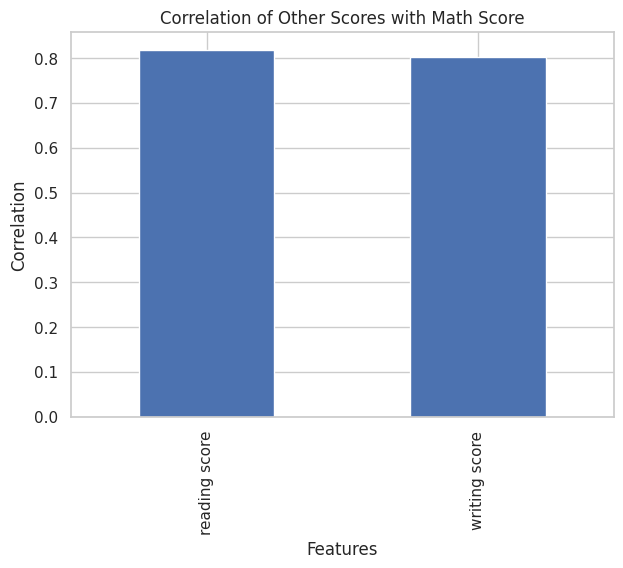

In [46]:
plt.figure(figsize=(7, 5))

math_corr.plot(kind="bar")

plt.title("Correlation of Other Scores with Math Score")
plt.xlabel("Features")
plt.ylabel("Correlation")

plt.show()

Interpretation: The output ranks reading and writing scores by their linear association with math score. Use the actual values to identify which relationship is strongest and which is weakest.

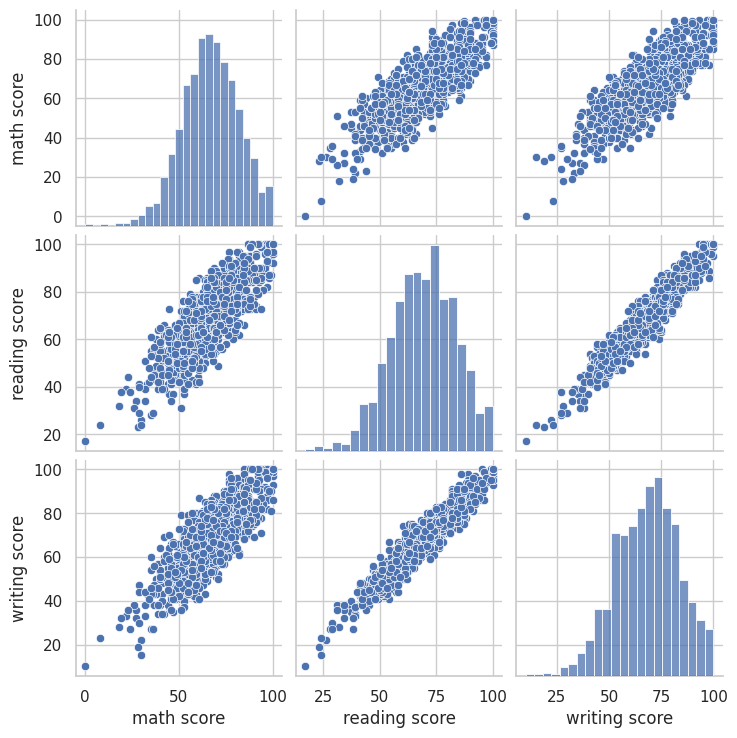

In [47]:
sns.pairplot(
    df[numerical_cols],
    diag_kind="hist"
)

plt.show()

Interpretation: The pairplot shows all three examination score distributions and their pairwise relationships. It helps identify common patterns and potential unusual observations across multiple numerical features.

In [48]:
combined_scores = df.pivot_table(
    index="gender",
    columns="test preparation course",
    values="math score",
    aggfunc="mean"
)

print(combined_scores)

test preparation course  completed       none
gender                                       
female                   67.195652  61.670659
male                     72.339080  66.688312


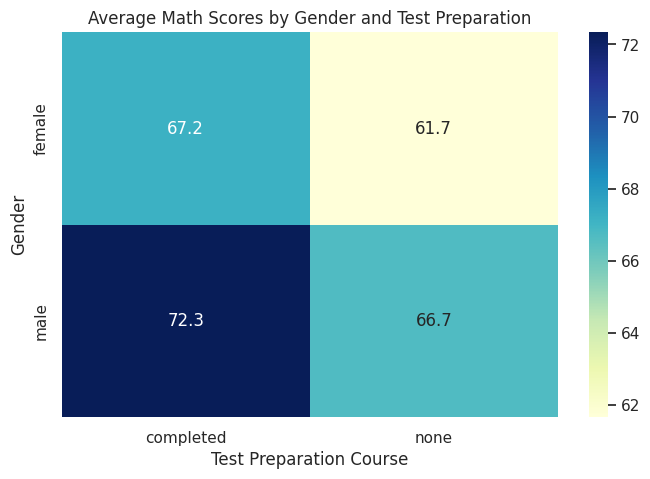

In [49]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    combined_scores,
    annot=True,
    cmap="YlGnBu",
    fmt=".1f"
)

plt.title("Average Math Scores by Gender and Test Preparation")
plt.xlabel("Test Preparation Course")
plt.ylabel("Gender")

plt.show()

Interpretation: The heatmap compares average math scores across combinations of gender and test preparation status. It helps identify whether score differences between preparation groups appear similar for both genders.

In [50]:
outlier_results = []

for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        "Feature": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers)
    })

outlier_df = pd.DataFrame(outlier_results)

outlier_df

,Feature,Lower Bound,Upper Bound,Outlier Count
0,math score,27.000,107.000,8
1,reading score,29.000,109.000,6
2,writing score,25.875,110.875,5


Interpretation: The table identifies potential outliers in math, reading, and writing scores using the IQR method. These observations should be investigated rather than automatically removed.

In [51]:
Q1 = df["math score"].quantile(0.25)
Q3 = df["math score"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

unusual_math_scores = df[
    (df["math score"] < lower_bound) |
    (df["math score"] > upper_bound)
]

print("Potential unusual observations:",
      len(unusual_math_scores))

unusual_math_scores.head(10)

Potential unusual observations: 8


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
17,female,group B,some high school,free/reduced,none,18,32,28
59,female,group C,some high school,free/reduced,none,0,17,10
145,female,group C,some college,free/reduced,none,22,39,33
338,female,group B,some high school,free/reduced,none,24,38,27
466,female,group D,associate's degree,free/reduced,none,26,31,38
787,female,group B,some college,standard,none,19,38,32
842,female,group B,high school,free/reduced,completed,23,44,36
980,female,group B,high school,free/reduced,none,8,24,23


Interpretation: The selected records have math scores outside the IQR-based limits. Such observations may represent students with unusually low or high marks, but they are not necessarily errors.

## Final Findings

1. The dataset contains 1,000 students and 8 variables, including student background and examination scores.

2. The math score histogram provides an overview of the distribution and variation in student performance.

3. Reading and writing scores can be compared with math scores to identify relationships between different academic subjects.

4. Test preparation status can be compared with math score distributions to explore possible differences between the two groups.

5. Parental education categories can be examined to identify differences in students' math scores.

6. The correlation heatmap helps identify the strength and direction of linear relationships among math, reading, and writing scores.

7. Multivariate analysis allows the comparison of math scores across combinations of gender and test preparation status.

8. Boxplots and IQR analysis help identify potential unusual score observations that may require investigation before future modeling.

## Conclusion

Exploratory Data Analysis provides an initial understanding of the Students Performance in Exams dataset. The analysis examines score distributions, relationships between academic subjects, and differences across student groups.

The findings can help guide future regression modeling by identifying relevant features and possible data-quality concerns. However, the observed associations do not prove that one factor causes a change in student performance.